In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.interpolate import griddata
from scipy.interpolate import UnivariateSpline

### Smooth spline utilizing Scipy UnivariateSpline

The spline function is obtained from minimizing:
$$ \left| \sum_i^n \left(\frac{y_i - spl(x_i)}{\sigma_i} \right)^2 - s\;n \right|, $$

$$ \sigma_i = \text{sem}_i = \sqrt{ \frac{1}{m (m-1)} \sum_{j=1}^{m} (y_i - y_{ij})^2 } + 10^{-10}. $$

The default values: $s=1$, $k=3$ (spline degree). 

In [2]:
def smooth_spline(x, y, y_std, s_factor=1, k=3):
    """
    Cubic smoothing spline with automatic smoothing chosen so that
    the mean‑squared error roughly equals s_factor × σ².
    If you have y‑errors, pass `w = 1/σ` to UnivariateSpline instead.
    """

    non_zero_idx = np.argwhere(y>0).flatten()
    x = x[non_zero_idx]
    y = y[non_zero_idx]
    y_std = y_std[non_zero_idx]

    # sort, because spline routines need monotonic x
    idx = np.argsort(x)
    y_std = np.maximum(y_std, 1e-10) 

    x = x[idx]
    y = y[idx]
    w = 1/y_std[idx]

    sp = UnivariateSpline(x, y, w=w, k=k, s=s_factor * len(y))

    return sp

In [3]:
bk_spacing = 0.25
b_spacing = 0.15
grid_search_bk_size = 5
grid_search_b_size = 13

In [4]:
# ndRlist = [1, 2, 3, 4, 5, 10]
# ndRlist = [5, 10, 15, 20]
ndRlist = [1, 2, 3, 4, 5, 10, 20, 30, 60, 100, 300]
ndlist = [1, 2, 3, 4, 5, 10, 12, 15, 20, 30, 50, 60, 75, 100, 150, 300, 400, 750, 1000, 1500]
nslist = [60000, 30000, 20000, 15000, 12000, 6000, 5000, 4000, 3000, 2000, 1200, 1000, 800, 600, 400, 200, 150, 80, 60, 40]

### Single Grid Search Plot
Error bar: 95% confidence interval (degree of freedom = 5)
$$\text{CI} = y_i \pm 2.571 \times \sigma_i $$

In [5]:
df = pd.read_csv("../data/gridSearch_SomaNoise/coeff_infty/dendrite_noise_0.35/max_points_df.csv")

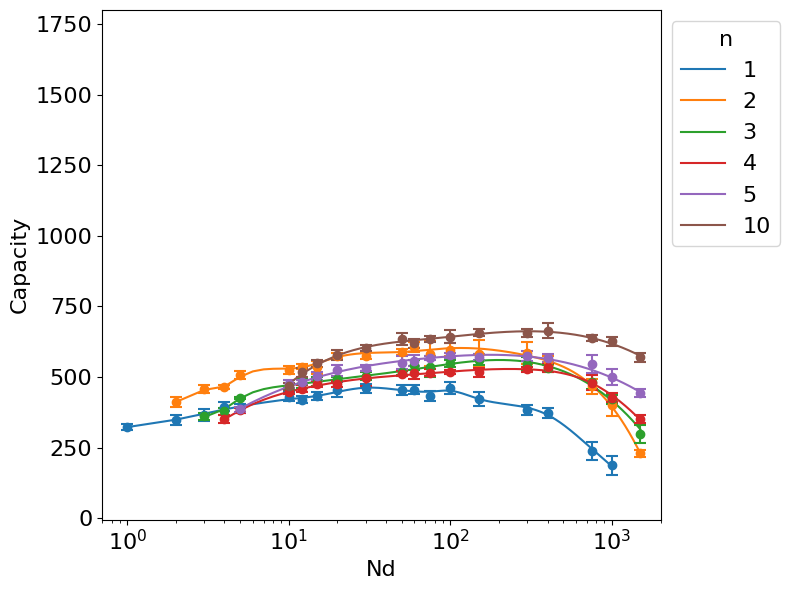

In [6]:
plt.figure(figsize=(8, 6))

# for ndR_idx, ndR_value in enumerate(ndRlist):
for ndR_idx, ndR_value in enumerate([1, 2, 3, 4, 5, 10]):
    subset = df[df['ndR'] == ndR_value]
    subset= subset.loc[subset.groupby(['capacity', 'nd'])['b'].idxmax()]
    subset = subset.sort_values("nd")
    max_nd = subset['nd'].max()
    min_nd = subset['nd'].min()
    try:
        nd_plot_list = np.linspace(min_nd, max_nd, int(max_nd-min_nd))
    except:
        print("Skipping ndR =", ndR_value)
    try:
        xs = np.log(subset['nd'].to_numpy())
        ys = subset['capacity'].to_numpy()
        y_sem = subset['sem'].to_numpy()
        spline = smooth_spline(np.log(subset['nd'].to_numpy()), subset['capacity'].to_numpy(), y_sem)
        fitted_capacity = spline(np.log(nd_plot_list))

        # print(spline.get_coeffs())

        plt.plot(nd_plot_list, fitted_capacity, label=f"{ndR_value}", c=f"C{ndR_idx}")
    except: pass

    plt.errorbar(
        x=subset['nd'],
        y=subset['capacity'],
        yerr=2.571*subset['sem'], 
        fmt='o',  
        capsize=4,
        capthick=1.5,
        elinewidth=1.5, 
        c=f"C{ndR_idx}"
    )

# Set x-axis to log scale
plt.xscale('log')

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.ylim(-5, 1800)
plt.xlim(0.7, 2000)

# Add labels and title
plt.xlabel('Nd', fontsize=16)
plt.ylabel('Capacity', fontsize=16)

# Move legend outside the plot
plt.legend(bbox_to_anchor=(1.0, 1), loc='upper left', title='n', fontsize=16, title_fontsize=16)

# plt.title('w/ interaction, no nonlinearity', fontsize=16)

# plt.savefig("../tmp_figures/capacity_vs_Nd_int_noNonlinearity.svg", bbox_inches='tight')

plt.tight_layout()

### Single Grid Search Plot: one $n$, same noise level, different coeff's

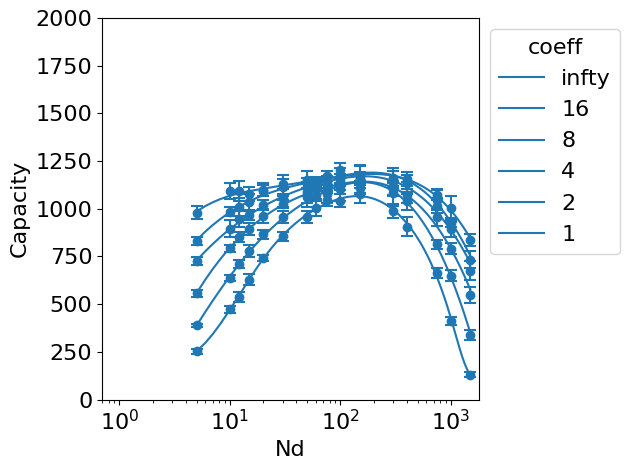

In [7]:
noise_level = 0.1
noise_mode = "dendrite"

file_path_list = [f"../data/gridSearch_SomaNoise/coeff_infty/{noise_mode}_noise_{noise_level}/max_points_df.csv", 
                  f"../data/gridSearch_SomaNoise/coeff_16/{noise_mode}_noise_{noise_level}/max_points_df.csv", 
                  f"../data/gridSearch_SomaNoise/coeff_8/{noise_mode}_noise_{noise_level}/max_points_df.csv", 
                  f"../data/gridSearch_SomaNoise/coeff_4/{noise_mode}_noise_{noise_level}/max_points_df.csv",
                  f"../data/gridSearch_SomaNoise/coeff_2/{noise_mode}_noise_{noise_level}/max_points_df.csv",
                  f"../data/gridSearch_SomaNoise/coeff_1/{noise_mode}_noise_{noise_level}/max_points_df.csv"]


df_name_list = ["infty", "16", "8", "4", "2", "1"]

dfs = []
for file_path in file_path_list:
    try:
        dfs.append(pd.read_csv(file_path))
    except:
        dfs.append(pd.DataFrame())  # empty DataFrame on failure

ndR_value = 5
ndR_idx = 0

for df_idx, df_name in enumerate(df_name_list):
    df = dfs[df_idx]
    if df.empty:
        continue
    subset = df[df['ndR'] == ndR_value]
    subset= subset.loc[subset.groupby(['capacity', 'nd'])['b'].idxmax()]
    subset = subset.sort_values("nd")
    max_nd = subset['nd'].max()
    min_nd = subset['nd'].min()
    nd_plot_list = np.linspace(min_nd, max_nd, int(max_nd-min_nd))
    try:
        xs = np.log(subset['nd'].to_numpy())
        ys = subset['capacity'].to_numpy()
        y_sem = subset['sem'].to_numpy()
        spline = smooth_spline(np.log(subset['nd'].to_numpy()), subset['capacity'].to_numpy(), y_sem)
        fitted_capacity = spline(np.log(nd_plot_list))

        # print(spline.get_coeffs())

        plt.plot(nd_plot_list, fitted_capacity, label=f"{df_name}", c=f"C{ndR_idx}")
    except: pass

    plt.errorbar(
        x=subset['nd'],
        y=subset['capacity'],
        yerr=2.571*subset['sem'], 
        fmt='o',  
        capsize=4,
        capthick=1.5,
        elinewidth=1.5, 
        c=f"C{ndR_idx}"
    )

# Set x-axis to log scale
plt.xscale('log')

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.ylim(0, 2000)
plt.xlim(0.7, 1800)

# Add labels and title
plt.xlabel('Nd', fontsize=16)
plt.ylabel('Capacity', fontsize=16)

# Move legend outside the plot
plt.legend(bbox_to_anchor=(1.0, 1), loc='upper left', title='coeff', fontsize=16, title_fontsize=16)

# plt.savefig("capacity_vs_nd_rhomax.svg", bbox_inches='tight')

plt.tight_layout()

### Multi Grid Search Plot: different $n$'s, different coeff's, same noise level

Text(0.5, 1.07, 'w/o interaction, coeffs=[infty, 16, 8, 4, 2, 1]\n noise mode = dendrite, noise level = 0.1')

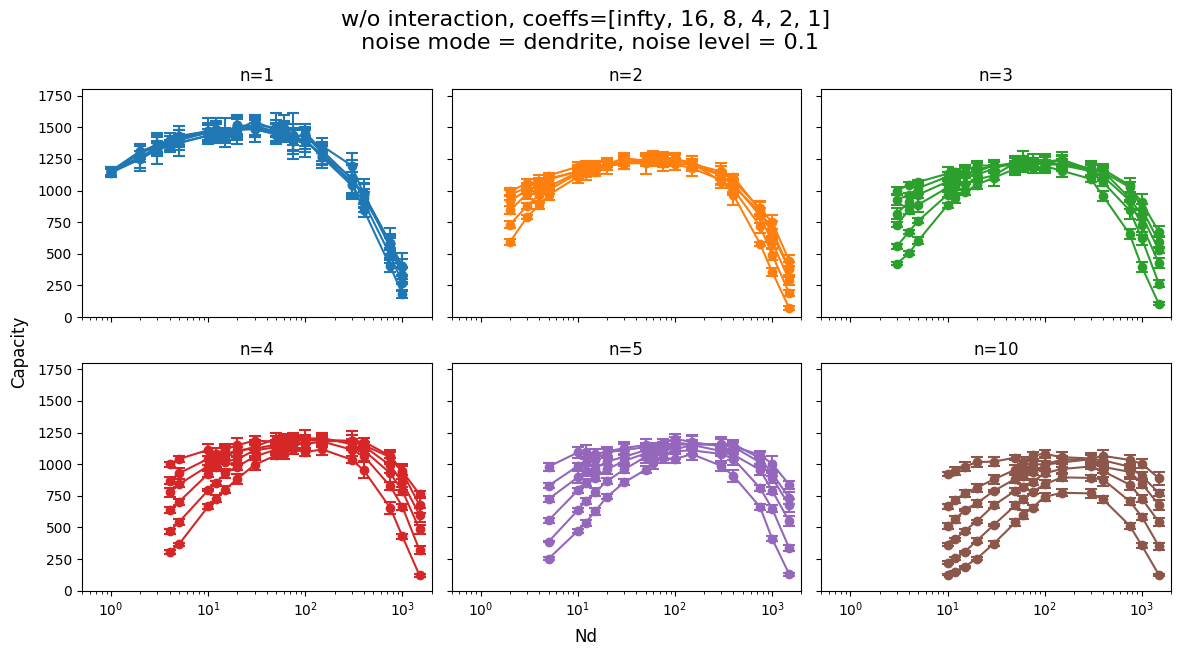

In [8]:
noise_level = 0.1
noise_mode = "dendrite"

file_path_list = [f"../data/gridSearch_SomaNoise/coeff_infty/{noise_mode}_noise_{noise_level}/max_points_df.csv", 
                  f"../data/gridSearch_SomaNoise/coeff_16/{noise_mode}_noise_{noise_level}/max_points_df.csv", 
                  f"../data/gridSearch_SomaNoise/coeff_8/{noise_mode}_noise_{noise_level}/max_points_df.csv", 
                  f"../data/gridSearch_SomaNoise/coeff_4/{noise_mode}_noise_{noise_level}/max_points_df.csv",
                  f"../data/gridSearch_SomaNoise/coeff_2/{noise_mode}_noise_{noise_level}/max_points_df.csv",
                  f"../data/gridSearch_SomaNoise/coeff_1/{noise_mode}_noise_{noise_level}/max_points_df.csv"]


df_name_list = ["infty", "16", "8", "4", "2", "1"]

ndRlist = [1, 2, 3, 4, 5, 10]

n_panels = len(ndRlist)
n_rows = int(np.floor(np.sqrt(n_panels)))
n_cols = int(np.ceil(n_panels / n_rows))

dfs = []
for file_path in file_path_list:
    try:
        dfs.append(pd.read_csv(file_path))
    except:
        dfs.append(pd.DataFrame())  # empty DataFrame on failure
fig, ax = plt.subplots(n_rows, n_cols, sharex=True, sharey=True, figsize=(12, 6))

for ndR_idx, ndR_value in enumerate(ndRlist):
    ax_i = ndR_idx//n_cols
    ax_j = ndR_idx%n_cols
    for df_idx, df_name in enumerate(df_name_list):
        df = dfs[df_idx]
        if df.empty:
            continue
        subset = df[df['ndR'] == ndR_value]
        subset= subset.loc[subset.groupby(['capacity', 'nd'])['b'].idxmax()]
        subset = subset.sort_values("nd")
        max_nd = subset['nd'].max()
        min_nd = subset['nd'].min()
        nd_plot_list = np.linspace(min_nd, max_nd, int(max_nd-min_nd))
        try:
            xs = np.log(subset['nd'].to_numpy())
            ys = subset['capacity'].to_numpy()
            y_sem = subset['sem'].to_numpy()
            # spline = smooth_spline(np.log(subset['nd'].to_numpy()), subset['capacity'].to_numpy(), y_sem)
            # fitted_capacity = spline(np.log(nd_plot_list))

            # ax[ax_i, ax_j].plot(nd_plot_list, fitted_capacity, label=f"{df_name}", c=f"C{ndR_idx}")
            ax[ax_i, ax_j].plot(subset['nd'], subset['capacity'], label=f"{ndR_value}", c=f"C{ndR_idx}") # Original points line
        except: pass

        ax[ax_i, ax_j].errorbar(
            x=subset['nd'],
            y=subset['capacity'],
            yerr=2.571*subset['sem'], 
            fmt='o',  
            capsize=4,
            capthick=1.5,
            elinewidth=1.5, 
            c=f"C{ndR_idx}"
        )

    ax[ax_i, ax_j].set_xlim(0.5, 2000)
    ax[ax_i, ax_j].set_ylim(0, 1800)
    # ax[ax_i, ax_j].set_xlabel("Nd")
    # ax[ax_i, ax_j].set_ylabel("capacity")
    ax[ax_i, ax_j].set_xscale("log")
    ax[ax_i, ax_j].set_title(f"n={ndR_value}") 
plt.tight_layout(rect=(0.03,0.03,1,1))
fig.supxlabel("Nd")
fig.supylabel("Capacity")
fig.suptitle(f"w/o interaction, coeffs=[infty, 16, 8, 4, 2, 1]\n noise mode = {noise_mode}, noise level = {noise_level}", fontsize=16, y=1.07)

# plt.savefig("../tmp_figures/capacity_vs_Nd_Int_multiPanels.svg", bbox_inches='tight')


Skipping ndR = 1 df = 0.6


Text(0.5, 1.07, 'w/o interaction, noise level=[0, 0.1, 0.3, 0.5, 0.7, 0.9]\n noise mode = dendrite, coeff = infty')

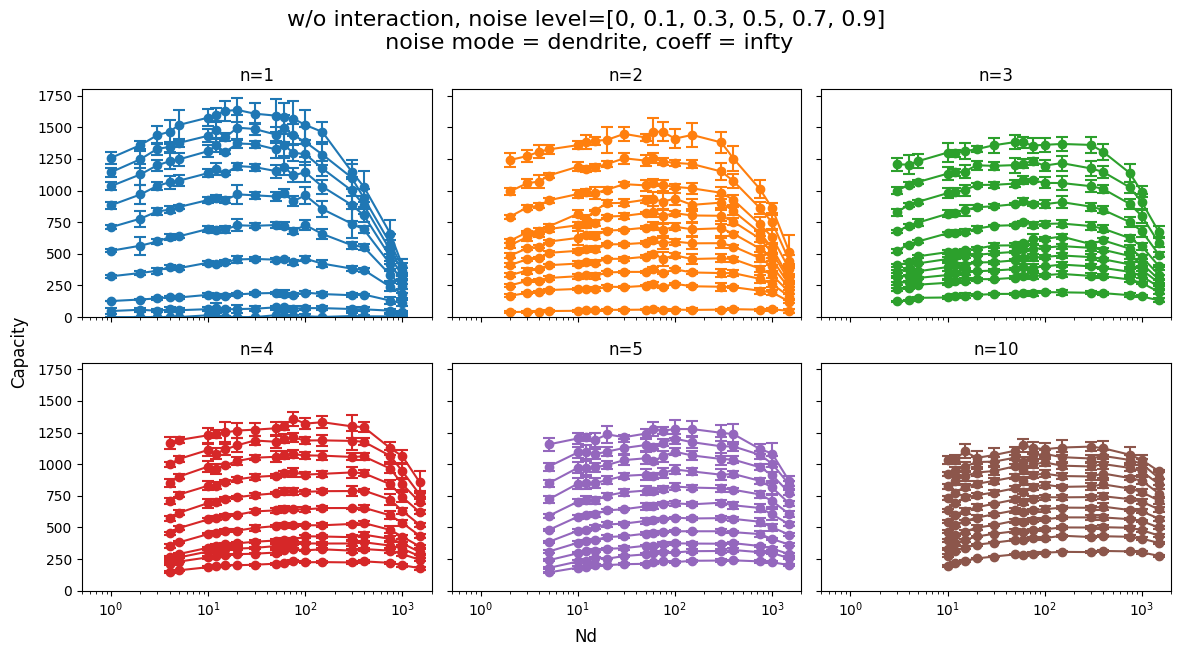

In [9]:
coeff = "infty"
noise_mode = "dendrite"

# file_path_list = [f"../data/gridSearch_standard/60000/coeff_{coeff}/max_points_df.csv", 
#                   f"../data/gridSearch_SomaNoise/coeff_{coeff}/{noise_mode}_noise_0.1/max_points_df.csv", 
#                   f"../data/gridSearch_SomaNoise/coeff_{coeff}/{noise_mode}_noise_0.3/max_points_df.csv", 
#                   f"../data/gridSearch_SomaNoise/coeff_{coeff}/{noise_mode}_noise_0.5/max_points_df.csv", 
#                   f"../data/gridSearch_SomaNoise/coeff_{coeff}/{noise_mode}_noise_0.7/max_points_df.csv",
#                   f"../data/gridSearch_SomaNoise/coeff_{coeff}/{noise_mode}_noise_0.9/max_points_df.csv"]


df_name_list = ["0", "0.1", "0.15", "0.2", "0.25", "0.3", "0.35", "0.4", "0.45", "0.5", "0.6", "0.7", "0.9"]

file_path_list = [f"../data/gridSearch_standard/60000/coeff_{coeff}/max_points_df.csv"] + [f"../data/gridSearch_SomaNoise/coeff_{coeff}/{noise_mode}_noise_{noise}/max_points_df.csv" for noise in df_name_list[1:]]

ndRlist = [1, 2, 3, 4, 5, 10]

n_panels = len(ndRlist)
n_rows = int(np.floor(np.sqrt(n_panels)))
n_cols = int(np.ceil(n_panels / n_rows))

dfs = []
for file_path in file_path_list:
    try:
        dfs.append(pd.read_csv(file_path))
    except:
        dfs.append(pd.DataFrame())  # empty DataFrame on failure
fig, ax = plt.subplots(n_rows, n_cols, sharex=True, sharey=True, figsize=(12, 6))

for ndR_idx, ndR_value in enumerate(ndRlist):
    ax_i = ndR_idx//n_cols
    ax_j = ndR_idx%n_cols
    for df_idx, df_name in enumerate(df_name_list):
        df = dfs[df_idx]
        if df.empty:
            continue
        subset = df[df['ndR'] == ndR_value]
        subset= subset.loc[subset.groupby(['capacity', 'nd'])['b'].idxmax()]
        subset = subset.sort_values("nd")
        max_nd = subset['nd'].max()
        min_nd = subset['nd'].min()
        try:
            nd_plot_list = np.linspace(min_nd, max_nd, int(max_nd-min_nd))
        except:
            print("Skipping ndR =", ndR_value, "df =", df_name)
        try:
            xs = np.log(subset['nd'].to_numpy())
            ys = subset['capacity'].to_numpy()
            y_sem = subset['sem'].to_numpy()
            # spline = smooth_spline(np.log(subset['nd'].to_numpy()), subset['capacity'].to_numpy(), y_sem)
            # fitted_capacity = spline(np.log(nd_plot_list))

            # ax[ax_i, ax_j].plot(nd_plot_list, fitted_capacity, label=f"{df_name}", c=f"C{ndR_idx}")
            ax[ax_i, ax_j].plot(subset['nd'], subset['capacity'], label=f"{ndR_value}", c=f"C{ndR_idx}") # Original points line
        except: pass

        ax[ax_i, ax_j].errorbar(
            x=subset['nd'],
            y=subset['capacity'],
            yerr=2.571*subset['sem'], 
            fmt='o',  
            capsize=4,
            capthick=1.5,
            elinewidth=1.5, 
            c=f"C{ndR_idx}"
        )

    ax[ax_i, ax_j].set_xlim(0.5, 2000)
    ax[ax_i, ax_j].set_ylim(0, 1800)
    # ax[ax_i, ax_j].set_xlabel("Nd")
    # ax[ax_i, ax_j].set_ylabel("capacity")
    ax[ax_i, ax_j].set_xscale("log")
    ax[ax_i, ax_j].set_title(f"n={ndR_value}") 
plt.tight_layout(rect=(0.03,0.03,1,1))
fig.supxlabel("Nd")
fig.supylabel("Capacity")
fig.suptitle(f"w/o interaction, noise level=[0, 0.1, 0.3, 0.5, 0.7, 0.9]\n noise mode = {noise_mode}, coeff = {coeff}", fontsize=16, y=1.07)

# plt.savefig("../tmp_figures/capacity_vs_Nd_Int_multiPanels.svg", bbox_inches='tight')


In [10]:
noise_str_list = ["0", "0.1", "0.15", "0.2", "0.25", "0.3", "0.35", "0.4", "0.45", "0.5", "0.6", "0.7", "0.9"]
noise_list = [0.0, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.9]
noise_mode = "synapse"
n_trials = 6
coeff = "infty"

In [11]:
file_path0 = f"../data/gridSearch_SomaNoise/coeff_{coeff}"

df_noise = pd.DataFrame(data=None)
dfs = []
# try to read the zero noise file first
try:
    tmp_df = pd.read_csv(f"../data/gridSearch_standard/60000/coeff_{coeff}/max_points_df.csv")
    tmp_df['noise'] = "0"
    dfs.append(tmp_df)
except:
    dfs.append(pd.DataFrame())  # empty DataFrame on failure
# read other noise files
for noise_idx, noise in enumerate(noise_list[1:]):
    noise_str = noise_str_list[1:][noise_idx]
    file_path = f"{file_path0}/{noise_mode}_noise_{noise_str}/max_points_df.csv"
    try:
        tmp_df = pd.read_csv(file_path)
        tmp_df['noise'] = noise_str
        dfs.append(tmp_df)
    except:
        dfs.append(pd.DataFrame())  # empty DataFrame on failure

df = pd.concat(dfs, ignore_index=True)


### Capacity vs noise for a fixed Nd

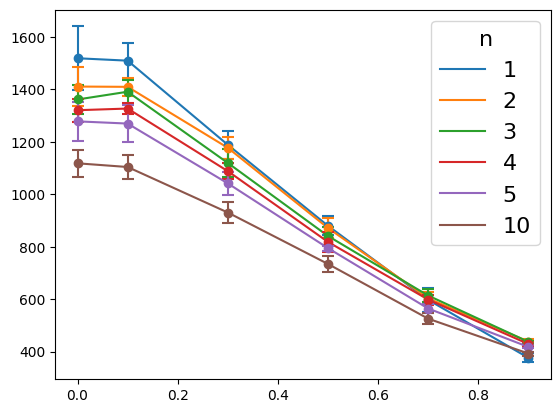

In [12]:
nd=100
ns=600
subset = df[df['nd'] == nd]
for ndR_idx, ndR in enumerate(ndRlist):
    subset_ndR = subset[subset['ndR'] == ndR]
    subset_ndR = subset_ndR.loc[subset_ndR.groupby(['capacity', 'noise'])['b'].idxmax()]
    subset_ndR = subset_ndR.sort_values("noise")
    plt.plot(subset_ndR['noise'].to_numpy().astype(float), subset_ndR['capacity'], label=f"{ndR}", c=f"C{ndR_idx}")
    plt.errorbar(
        x=subset_ndR['noise'].to_numpy().astype(float),
        y=subset_ndR['capacity'],
        yerr=2.571*subset_ndR['sem'], 
        fmt='o',  
        capsize=4,
        capthick=1.5,
        elinewidth=1.5, 
        c=f"C{ndR_idx}"
    )
plt.legend(title='n', fontsize=16, title_fontsize=16, bbox_to_anchor=(1., 1))

### Capacity vs noise, Capacity is the maximum one across Nd

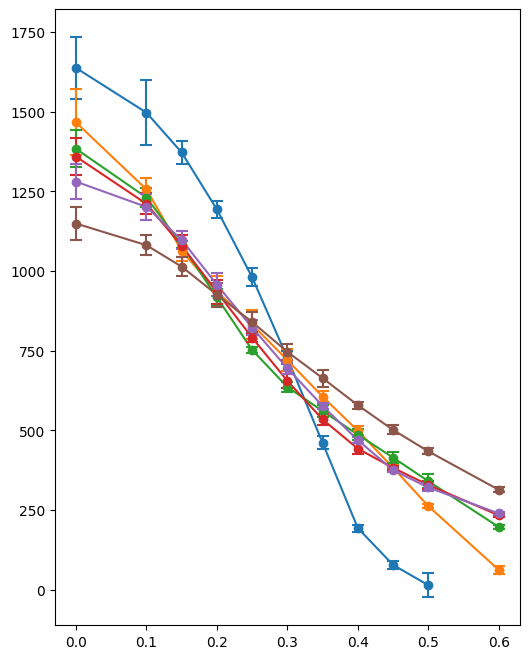

In [17]:
plt.figure(figsize=(6, 8))
max_df = df.loc[df.groupby(['noise', 'ndR'])['capacity'].idxmax()]
for ndR_idx, ndR in enumerate(ndRlist):
    subset_ndR = max_df[max_df['ndR'] == ndR]
    subset_ndR = subset_ndR.sort_values("noise")
    plt.plot(subset_ndR['noise'].to_numpy().astype(float), subset_ndR['capacity'], label=f"{ndR}", c=f"C{ndR_idx}")
    plt.errorbar(
        x=subset_ndR['noise'].to_numpy().astype(float),
        y=subset_ndR['capacity'],
        yerr=2.571*subset_ndR['sem'], 
        fmt='o',  
        capsize=4,
        capthick=1.5,
        elinewidth=1.5, 
        c=f"C{ndR_idx}"
    )
# plt.legend(title='n', fontsize=16, title_fontsize=16, bbox_to_anchor=(1., 1))

### Multiple panels of capacity vs noise, each panel corresponds to a fixed Nd

Text(0.5, 1.07, 'w/o interaction, coeff = infty\n noise mode = dendrite')

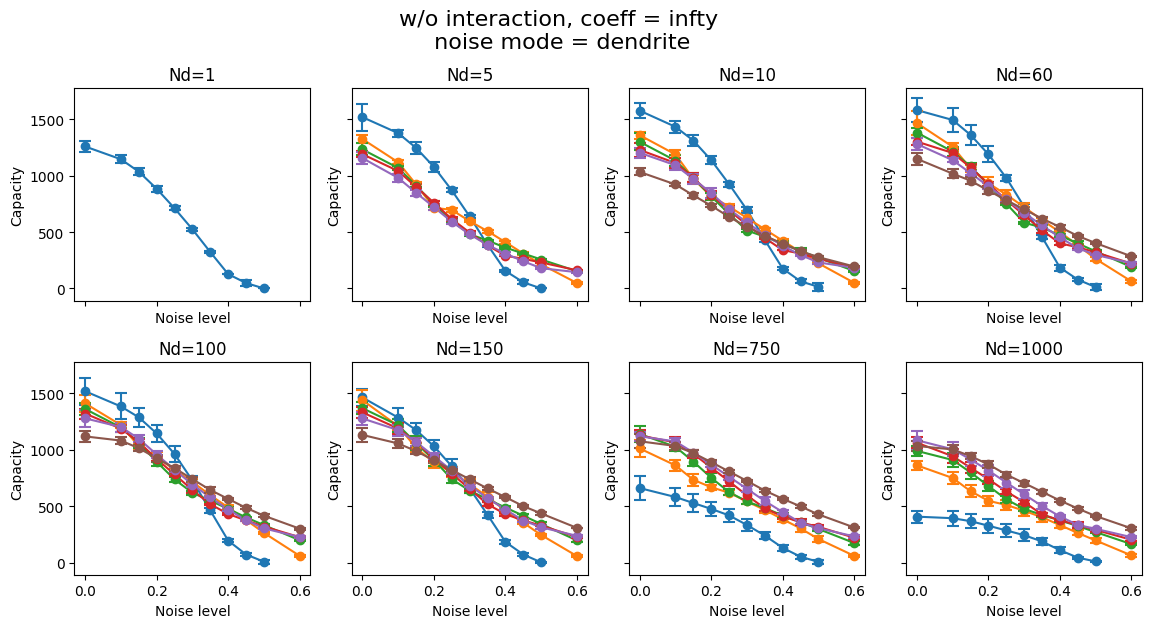

In [89]:
nd_tmp_plot_list = [1, 5, 10, 60, 100, 150, 750, 1000]
n_panels = len(nd_tmp_plot_list)
n_rows = int(np.floor(np.sqrt(n_panels)))
n_cols = int(np.ceil(n_panels / n_rows))

fig, ax = plt.subplots(n_rows, n_cols, sharex=True, sharey=True, figsize=(12, 6))
for nd_idx, nd in enumerate(nd_tmp_plot_list):
    ax_i = nd_idx//n_cols
    ax_j = nd_idx%n_cols
    subset = df[df['nd'] == nd]
    for ndR_idx, ndR in enumerate(ndRlist):
        subset_ndR = subset[subset['ndR'] == ndR]
        subset_ndR = subset_ndR.loc[subset_ndR.groupby(['capacity', 'noise'])['b'].idxmax()]
        subset_ndR = subset_ndR.sort_values("noise")
        ax[ax_i, ax_j].plot(subset_ndR['noise'].to_numpy().astype(float), subset_ndR['capacity'], label=f"{ndR}", c=f"C{ndR_idx}")
        ax[ax_i, ax_j].errorbar(
            x=subset_ndR['noise'].to_numpy().astype(float),
            y=subset_ndR['capacity'],
            yerr=2.571*subset_ndR['sem'], 
            fmt='o',  
            capsize=4,
            capthick=1.5,
            elinewidth=1.5, 
            c=f"C{ndR_idx}"
        )
    ax[ax_i, ax_j].set_title(f"Nd={nd}")
    ax[ax_i, ax_j].set_xlabel("Noise level")
    ax[ax_i, ax_j].set_ylabel("Capacity")
plt.tight_layout(rect=(0.03,0.03,1,1))
fig.suptitle(f"w/o interaction, coeff = {coeff}\n noise mode = {noise_mode}", fontsize=16, y=1.07)

### Multiple panels of capacity vs Nd plots, each panel correspond to a noise level

Text(0.5, 1.07, 'w/o interaction, coeff = infty\n noise mode = dendrite')

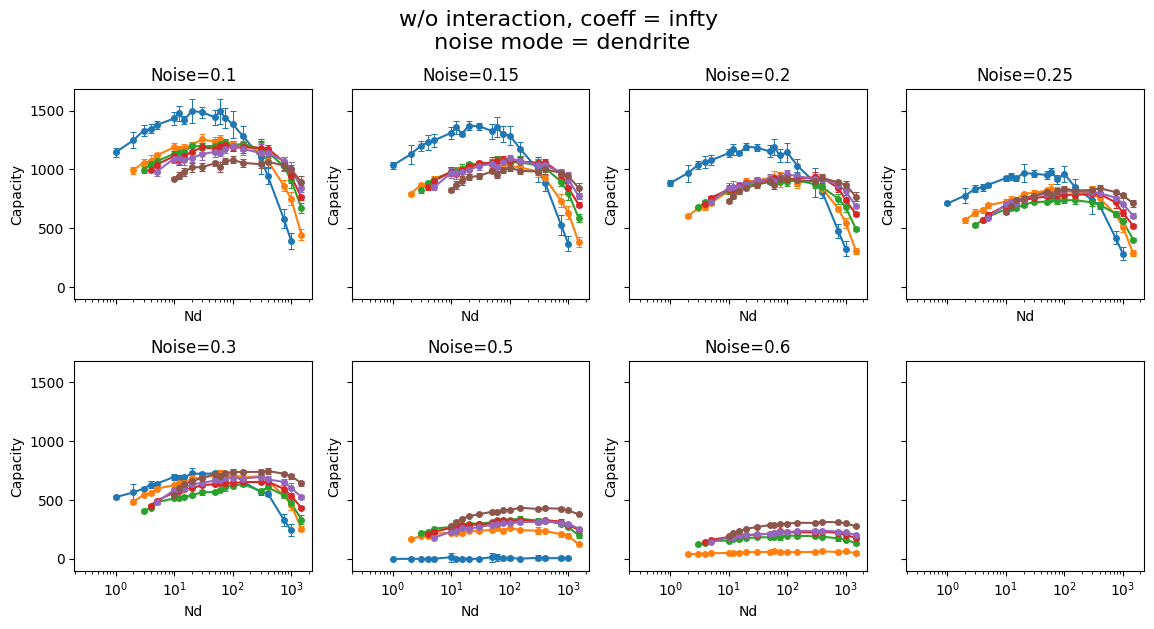

In [91]:
noise_tmp_plot_list = [0.1, 0.15, 0.2, 0.25, 0.3, 0.5, 0.6]
n_panels = len(noise_tmp_plot_list)
n_rows = int(np.floor(np.sqrt(n_panels)))
n_cols = int(np.ceil(n_panels / n_rows))    

fig, ax = plt.subplots(n_rows, n_cols, sharex=True, sharey=True, figsize=(12, 6))
for noise_idx, noise in enumerate(noise_tmp_plot_list):
    ax_i = noise_idx//n_cols
    ax_j = noise_idx%n_cols
    subset = df[df['noise'].astype(float) == noise]
    for ndR_idx, ndR in enumerate(ndRlist):
        subset_ndR = subset[subset['ndR'] == ndR]
        subset_ndR = subset_ndR.loc[subset_ndR.groupby(['capacity', 'nd'])['b'].idxmax()]
        subset_ndR = subset_ndR.sort_values("nd")
        ax[ax_i, ax_j].plot(subset_ndR['nd'], subset_ndR['capacity'], label=f"{ndR}", c=f"C{ndR_idx}")
        ax[ax_i, ax_j].errorbar(
            x=subset_ndR['nd'],
            y=subset_ndR['capacity'],
            yerr=2.571*subset_ndR['sem'], 
            fmt='o',  
            capsize=2,
            capthick=0.75,
            elinewidth=0.75, 
            c=f"C{ndR_idx}", 
            markersize=4
        )
    ax[ax_i, ax_j].set_title(f"Noise={noise}")
    ax[ax_i, ax_j].set_xlabel("Nd")
    ax[ax_i, ax_j].set_ylabel("Capacity")
    ax[ax_i, ax_j].set_xscale("log")
plt.tight_layout(rect=(0.03,0.03,1,1))
fig.suptitle(f"w/o interaction, coeff = {coeff}\n noise mode = {noise_mode}", fontsize=16, y=1.07)

In [66]:
noise_str_list = ["0", "0.1", "0.15", "0.2", "0.25", "0.3", "0.35", "0.4", "0.45", "0.5", "0.6", "0.7", "0.9"]
noise_list = [0.0, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.9]
noise_mode = "dendrite"
n_trials = 6
coeff = "infty"

In [72]:
file_path0 = f"../data/thetaY_record_no_gridSearch/coeff_{coeff}"

df_columns_names = ["nd", "ndR", "b", "bk", "beta"] + [f"thetaY_{i}" for i in range(n_trials)]
dfs = []
# try to read the zero noise file first
try:
    tmp_df = pd.read_csv(f"{file_path0}/noise_0.csv", header=None, names=df_columns_names)
    tmp_df['noise'] = "0"
    dfs.append(tmp_df)
except:
    dfs.append(pd.DataFrame())  # empty DataFrame on failure
# read other noise files
for noise_idx, noise in enumerate(noise_list[1:]):
    noise_str = noise_str_list[1:][noise_idx]
    file_path = f"{file_path0}/{noise_mode}_noise_{noise_str}.csv"
    try:
        tmp_df = pd.read_csv(file_path, header=None, names=df_columns_names)
        tmp_df['noise'] = noise_str
        dfs.append(tmp_df)
    except:
        dfs.append(pd.DataFrame())  # empty DataFrame on failure

df = pd.concat(dfs, ignore_index=True)

df = df[df["ndR"]!=df["nd"]] # remove the cases where ndR == nd

thetaY_columns = df.columns[5:11]
df['mean_thetaY'] = df[thetaY_columns].mean(axis=1)
df["sem_thetaY"] = df[thetaY_columns].sem(axis=1)
df = df.drop(columns=thetaY_columns)

### (bk, b, kappa, thetaY, n*kappa, init_signal) vs Nd, 6 panels, fixed noise level

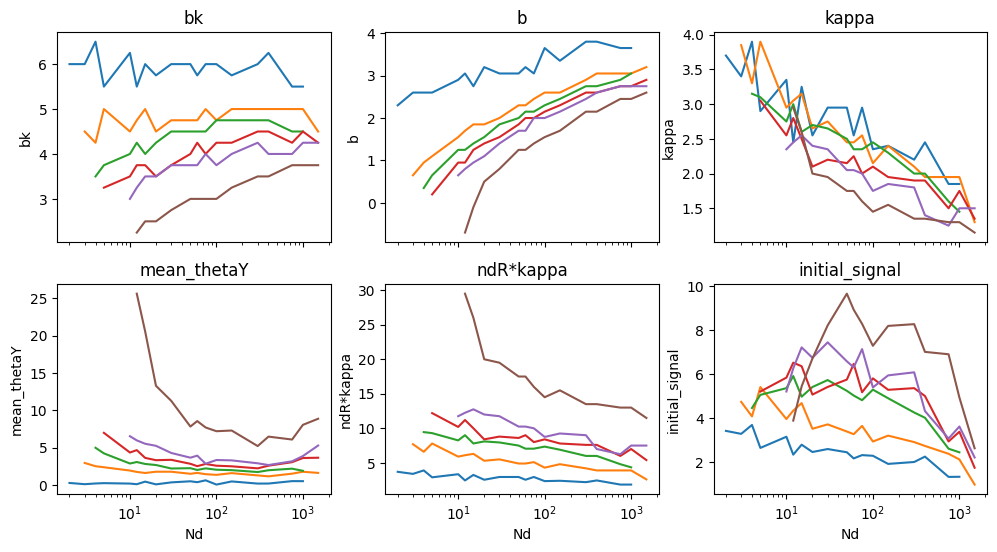

In [73]:
noise = 0

subset = df[df['noise'].astype(float) == noise]

n_panels = 6
n_rows = int(np.floor(np.sqrt(n_panels)))
n_cols = int(np.ceil(n_panels / n_rows))
fig, ax = plt.subplots(n_rows, n_cols, sharex=True, sharey=False, figsize=(12, 6))

# Panel 1: bk vs Nd
for ndR_idx, ndR in enumerate(ndRlist):
    subset_ndR = subset[subset['ndR'] == ndR]
    subset_ndR = subset_ndR.sort_values("nd")
    ax[0, 0].plot(subset_ndR['nd'], subset_ndR['bk'], label=f"{ndR}", c=f"C{ndR_idx}")
ax[0, 0].set_title("bk")
ax[0, 0].set_ylabel("bk")
ax[0, 0].set_xscale("log")

# Panel 2: b vs Nd
for ndR_idx, ndR in enumerate(ndRlist):
    subset_ndR = subset[subset['ndR'] == ndR]
    subset_ndR = subset_ndR.sort_values("nd")
    ax[0, 1].plot(subset_ndR['nd'], subset_ndR['b'], label=f"{ndR}", c=f"C{ndR_idx}")
ax[0, 1].set_title("b")
ax[0, 1].set_ylabel("b")
ax[0, 1].set_xscale("log")

# Panel 3: kappa vs Nd
for ndR_idx, ndR in enumerate(ndRlist):
    subset_ndR = subset[subset['ndR'] == ndR]
    subset_ndR = subset_ndR.sort_values("nd")
    ax[0, 2].plot(subset_ndR['nd'], subset_ndR['bk']-subset_ndR['b'], label=f"{ndR}", c=f"C{ndR_idx}")
ax[0, 2].set_title("kappa")
ax[0, 2].set_ylabel("kappa")
ax[0, 2].set_xscale("log") 

# Panel 4: mean_thetaY vs Nd
for ndR_idx, ndR in enumerate(ndRlist):
    subset_ndR = subset[subset['ndR'] == ndR]
    subset_ndR = subset_ndR.sort_values("nd")
    ax[1, 0].plot(subset_ndR['nd'], subset_ndR['mean_thetaY'], label=f"{ndR}", c=f"C{ndR_idx}")
ax[1, 0].set_title("mean_thetaY")
ax[1, 0].set_xlabel("Nd")
ax[1, 0].set_ylabel("mean_thetaY")
ax[1, 0].set_xscale("log")

# Panel 5: ndR*kappa vs Nd
for ndR_idx, ndR in enumerate(ndRlist):
    subset_ndR = subset[subset['ndR'] == ndR]
    subset_ndR = subset_ndR.sort_values("nd")
    ndR_kappa = ndR * (subset_ndR['bk'] - subset_ndR['b'])
    ax[1, 1].plot(subset_ndR['nd'], ndR_kappa, label=f"{ndR}", c=f"C{ndR_idx}")
ax[1, 1].set_title("ndR*kappa")
ax[1, 1].set_xlabel("Nd")
ax[1, 1].set_ylabel("ndR*kappa")
ax[1, 1].set_xscale("log")

# Panel 6: initial_signal vs Nd, initial_signal = ndR*kappa - thetaY
for ndR_idx, ndR in enumerate(ndRlist):
    subset_ndR = subset[subset['ndR'] == ndR]
    subset_ndR = subset_ndR.sort_values("nd")
    initial_signal = ndR * (subset_ndR['bk'] - subset_ndR['b']) - subset_ndR['mean_thetaY']
    ax[1, 2].plot(subset_ndR['nd'], initial_signal, label=f"{ndR}", c=f"C{ndR_idx}")
ax[1, 2].set_title("initial_signal")
ax[1, 2].set_xlabel("Nd")
ax[1, 2].set_ylabel("initial_signal")
ax[1, 2].set_xscale("log")

### (bk, b, kappa, thetaY, n*kappa, init_signal) vs noise, 6 panels, fixed Nd

Text(0.5, 1.07, 'w/o interaction, coeff = infty, Nd=75\n noise mode = dendrite')

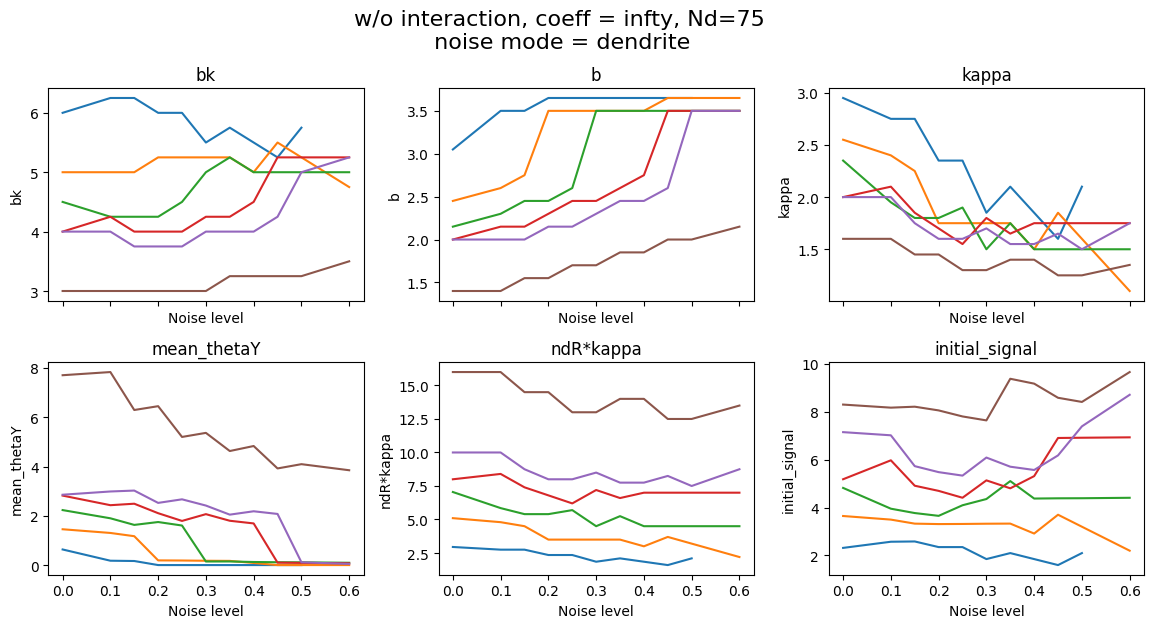

In [69]:
nd = 75
subset = df[df['nd'] == nd]

n_panels = 6
n_rows = int(np.floor(np.sqrt(n_panels)))
n_cols = int(np.ceil(n_panels / n_rows))
fig, ax = plt.subplots(n_rows, n_cols, sharex=True, sharey=False, figsize=(12, 6))

# Panel 1: bk vs noise
for ndR_idx, ndR in enumerate(ndRlist):
    subset_ndR = subset[subset['ndR'] == ndR]
    subset_ndR = subset_ndR.sort_values("noise")
    ax[0, 0].plot(subset_ndR['noise'].to_numpy().astype(float), subset_ndR['bk'], label=f"{ndR}", c=f"C{ndR_idx}")
ax[0, 0].set_title("bk")
ax[0, 0].set_ylabel("bk")
ax[0, 0].set_xlabel("Noise level")

# Panel 2: b vs noise
for ndR_idx, ndR in enumerate(ndRlist):
    subset_ndR = subset[subset['ndR'] == ndR]
    subset_ndR = subset_ndR.sort_values("noise")
    ax[0, 1].plot(subset_ndR['noise'].to_numpy().astype(float), subset_ndR['b'], label=f"{ndR}", c=f"C{ndR_idx}")
ax[0, 1].set_title("b")
ax[0, 1].set_ylabel("b")
ax[0, 1].set_xlabel("Noise level")

# Panel 3: kappa vs noise
for ndR_idx, ndR in enumerate(ndRlist):
    subset_ndR = subset[subset['ndR'] == ndR]
    subset_ndR = subset_ndR.sort_values("noise")
    ax[0, 2].plot(subset_ndR['noise'].to_numpy().astype(float), subset_ndR['bk']-subset_ndR['b'], label=f"{ndR}", c=f"C{ndR_idx}")
ax[0, 2].set_title("kappa")
ax[0, 2].set_ylabel("kappa")
ax[0, 2].set_xlabel("Noise level")

# Panel 4: mean_thetaY vs noise
for ndR_idx, ndR in enumerate(ndRlist):
    subset_ndR = subset[subset['ndR'] == ndR]
    subset_ndR = subset_ndR.sort_values("noise")
    ax[1, 0].plot(subset_ndR['noise'].to_numpy().astype(float), subset_ndR['mean_thetaY'], label=f"{ndR}", c=f"C{ndR_idx}")
ax[1, 0].set_title("mean_thetaY")
ax[1, 0].set_xlabel("Noise level")
ax[1, 0].set_ylabel("mean_thetaY")

# Panel 5: ndR*kappa vs noise
for ndR_idx, ndR in enumerate(ndRlist):
    subset_ndR = subset[subset['ndR'] == ndR]
    subset_ndR = subset_ndR.sort_values("noise")
    ndR_kappa = ndR * (subset_ndR['bk'] - subset_ndR['b'])
    ax[1, 1].plot(subset_ndR['noise'].to_numpy().astype(float), ndR_kappa, label=f"{ndR}", c=f"C{ndR_idx}")
ax[1, 1].set_title("ndR*kappa")
ax[1, 1].set_xlabel("Noise level")
ax[1, 1].set_ylabel("ndR*kappa")

# Panel 6: initial_signal vs noise, initial_signal = ndR*kappa - thetaY
for ndR_idx, ndR in enumerate(ndRlist):
    subset_ndR = subset[subset['ndR'] == ndR]
    subset_ndR = subset_ndR.sort_values("noise")
    initial_signal = ndR * (subset_ndR['bk'] - subset_ndR['b']) - subset_ndR['mean_thetaY']
    ax[1, 2].plot(subset_ndR['noise'].to_numpy().astype(float), initial_signal, label=f"{ndR}", c=f"C{ndR_idx}")
ax[1, 2].set_title("initial_signal")
ax[1, 2].set_xlabel("Noise level")
ax[1, 2].set_ylabel("initial_signal")
plt.tight_layout(rect=(0.03,0.03,1,1))
fig.suptitle(f"w/o interaction, coeff = {coeff}, Nd={nd}\n noise mode = {noise_mode}", fontsize=16, y=1.07)

In [1]:
import numpy as np

In [25]:
vy0 = 10.5*np.sin(80/180*np.pi)
vy0/9.8 + np.sqrt((vy0*vy0/2/9.8-3.8)*2/9.8)

np.float64(1.636385862394685)

In [26]:
np.sqrt(10.5**2 - 2*9.8*3.8)

np.float64(5.980802621722272)

In [31]:
(0.5*5*0.4*0.4)/(0.5*5*0.4*0.4+2.5*0.213**2)*36

28.047076238380672

In [ ]:
1000/9.6*(70*1609/3600)**2/2

50980.247315457826

In [32]:
np.sqrt(3000/0.17*0.06**2-2*9.8*0.5*0.06)

np.float64(7.9335623628169625)

In [7]:
np.sqrt(1+4)*13/3

np.float64(9.689627902499089)

In [33]:
np.pi*np.sqrt(4/150)

np.float64(0.5130199320647456)

In [34]:
np.sqrt(6.6**3)

np.float64(16.95570700383797)

In [36]:
np.sqrt(3000/0.32)*0.0415

np.float64(4.018220221690195)